# ShopSmart E-commerce Project
Predict whether a visitor will buy (`Revenue`) using a Decision Tree. The data is imbalanced, so we check the model with **F1 score** (benchmark = 0.55).

## Import libraries

In [1]:
import numpy as np 
import pandas as pd 
import seaborn as sns 
import matplotlib.pyplot as plt

## Load the data

In [2]:
data = pd.read_csv("17) shop_smart_ecommerce.csv")
data.head(20)

,Administrative,Administrative_Duration,Informational,Informational_Duration,ProductRelated,ProductRelated_Duration,BounceRates,ExitRates,PageValues,SpecialDay,Month,OperatingSystems,Browser,Region,TrafficType,VisitorType,Weekend,Revenue
0,0,0.0,0,0.0,1,0.000000,0.200000,0.200000,0.0,0.0,Feb,1,1,1,1,Returning_Visitor,False,False
1,0,0.0,0,0.0,2,64.000000,0.000000,0.100000,0.0,0.0,Feb,2,2,1,2,Returning_Visitor,False,False
2,0,0.0,0,0.0,1,0.000000,0.200000,0.200000,0.0,0.0,Feb,4,1,9,3,Returning_Visitor,False,False
3,0,0.0,0,0.0,2,2.666667,0.050000,0.140000,0.0,0.0,Feb,3,2,2,4,Returning_Visitor,False,False
4,0,0.0,0,0.0,10,627.500000,0.020000,0.050000,0.0,0.0,Feb,3,3,1,4,Returning_Visitor,True,False
5,0,0.0,0,0.0,19,154.216667,0.015789,0.024561,0.0,0.0,Feb,2,2,1,3,Returning_Visitor,False,False
6,0,0.0,0,0.0,1,0.000000,0.200000,0.200000,0.0,0.4,Feb,2,4,3,3,Returning_Visitor,False,False
7,1,0.0,0,0.0,0,0.000000,0.200000,0.200000,0.0,0.0,Feb,1,2,1,5,Returning_Visitor,True,False
8,0,0.0,0,0.0,2,37.000000,0.000000,0.100000,0.0,0.8,Feb,2,2,2,3,Returning_Visitor,False,False
9,0,0.0,0,0.0,3,738.000000,0.000000,0.022222,0.0,0.4,Feb,2,4,1,2,Returning_Visitor,False,False


## Check data types and null values

In [3]:
data.info()

<class 'pandas.DataFrame'>
RangeIndex: 12330 entries, 0 to 12329
Data columns (total 18 columns):
 #   Column                   Non-Null Count  Dtype  
---  ------                   --------------  -----  
 0   Administrative           12330 non-null  int64  
 1   Administrative_Duration  12330 non-null  float64
 2   Informational            12330 non-null  int64  
 3   Informational_Duration   12330 non-null  float64
 4   ProductRelated           12330 non-null  int64  
 5   ProductRelated_Duration  12330 non-null  float64
 6   BounceRates              12330 non-null  float64
 7   ExitRates                12330 non-null  float64
 8   PageValues               12330 non-null  float64
 9   SpecialDay               12330 non-null  float64
 10  Month                    12330 non-null  str    
 11  OperatingSystems         12330 non-null  int64  
 12  Browser                  12330 non-null  int64  
 13  Region                   12330 non-null  int64  
 14  TrafficType              12330 no

There are no null values. `Month` and `VisitorType` are text, so we will encode them later.

## EDA (Exploratory Data Analysis)

### Null values and duplicate rows

In [4]:
print("Null values :", data.isnull().sum().sum())
print("Duplicate rows :", data.duplicated().sum())
data.describe()

Null values : 0
Duplicate rows : 125


,Administrative,Administrative_Duration,Informational,Informational_Duration,ProductRelated,ProductRelated_Duration,BounceRates,ExitRates,PageValues,SpecialDay,OperatingSystems,Browser,Region,TrafficType
count,12330.000000,12330.000000,12330.000000,12330.000000,12330.000000,12330.000000,12330.000000,12330.000000,12330.000000,12330.000000,12330.000000,12330.000000,12330.000000,12330.000000
mean,2.315166,80.818611,0.503569,34.472398,31.731468,1194.746220,0.022191,0.043073,5.889258,0.061427,2.124006,2.357097,3.147364,4.069586
std,3.321784,176.779107,1.270156,140.749294,44.475503,1913.669288,0.048488,0.048597,18.568437,0.198917,0.911325,1.717277,2.401591,4.025169
min,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,1.000000,1.000000,1.000000,1.000000
25%,0.000000,0.000000,0.000000,0.000000,7.000000,184.137500,0.000000,0.014286,0.000000,0.000000,2.000000,2.000000,1.000000,2.000000
50%,1.000000,7.500000,0.000000,0.000000,18.000000,598.936905,0.003112,0.025156,0.000000,0.000000,2.000000,2.000000,3.000000,2.000000
75%,4.000000,93.256250,0.000000,0.000000,38.000000,1464.157214,0.016813,0.050000,0.000000,0.000000,3.000000,2.000000,4.000000,4.000000
max,27.000000,3398.750000,24.000000,2549.375000,705.000000,63973.522230,0.200000,0.200000,361.763742,1.000000,8.000000,13.000000,9.000000,20.000000


### Target column (Revenue)
How many visitors buy and how many do not.

Revenue
False    10422
True      1908
Name: count, dtype: int64
Revenue
False    0.845255
True     0.154745
Name: proportion, dtype: float64


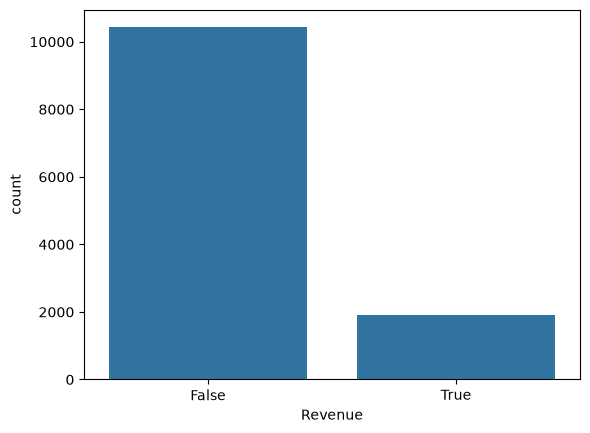

In [5]:
print(data["Revenue"].value_counts())
print(data["Revenue"].value_counts(normalize=True))
sns.countplot(x="Revenue", data=data)
plt.show()

Only a small part of the visitors buy, so the data is **imbalanced**. That is why we use F1 score and not accuracy.

### Buyers vs non-buyers

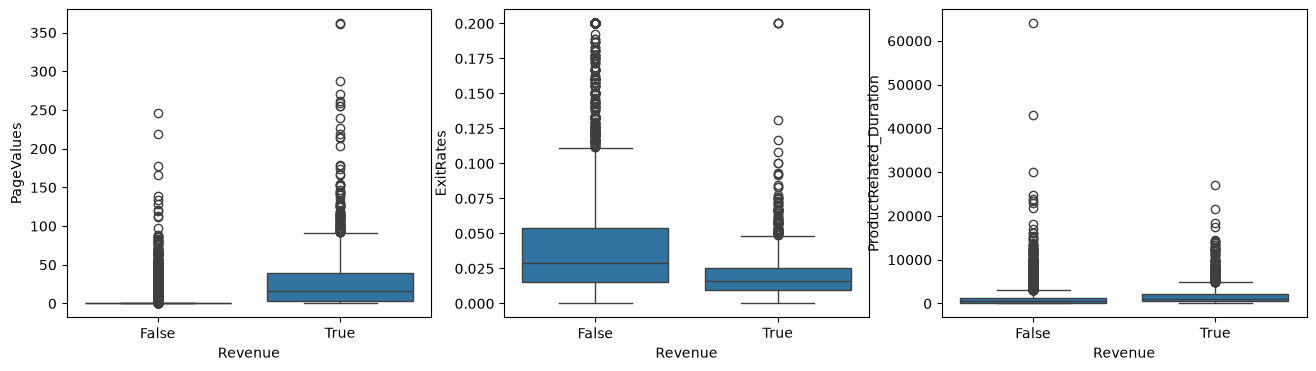

In [6]:
fig, ax = plt.subplots(1, 3, figsize=(16, 4))
sns.boxplot(x="Revenue", y="PageValues", data=data, ax=ax[0])
sns.boxplot(x="Revenue", y="ExitRates", data=data, ax=ax[1])
sns.boxplot(x="Revenue", y="ProductRelated_Duration", data=data, ax=ax[2])
plt.show()

### Purchase rate by VisitorType and Month

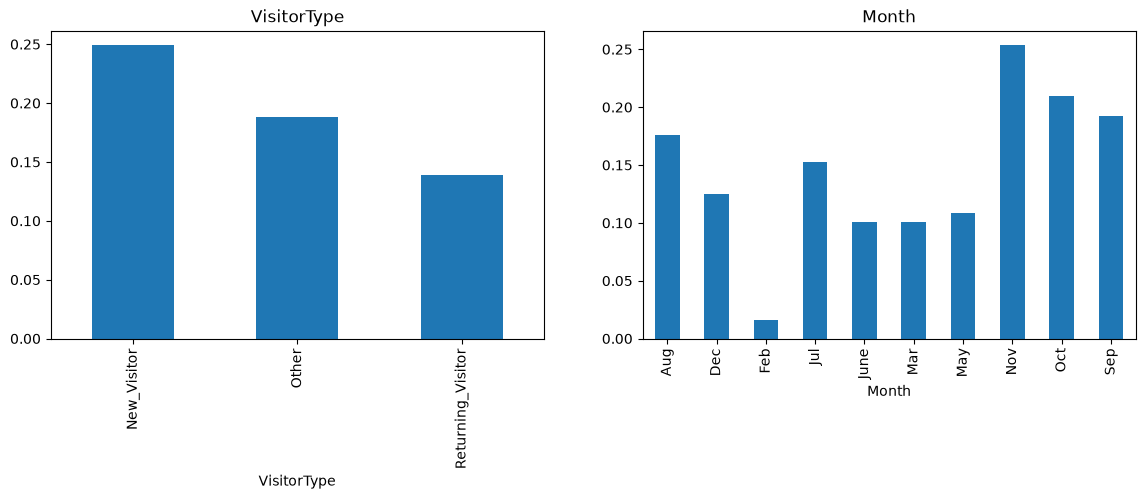

In [7]:
fig, ax = plt.subplots(1, 2, figsize=(14, 4))
data.groupby("VisitorType")["Revenue"].mean().plot(kind="bar", ax=ax[0], title="VisitorType")
data.groupby("Month")["Revenue"].mean().plot(kind="bar", ax=ax[1], title="Month")
plt.show()

### Correlation heatmap

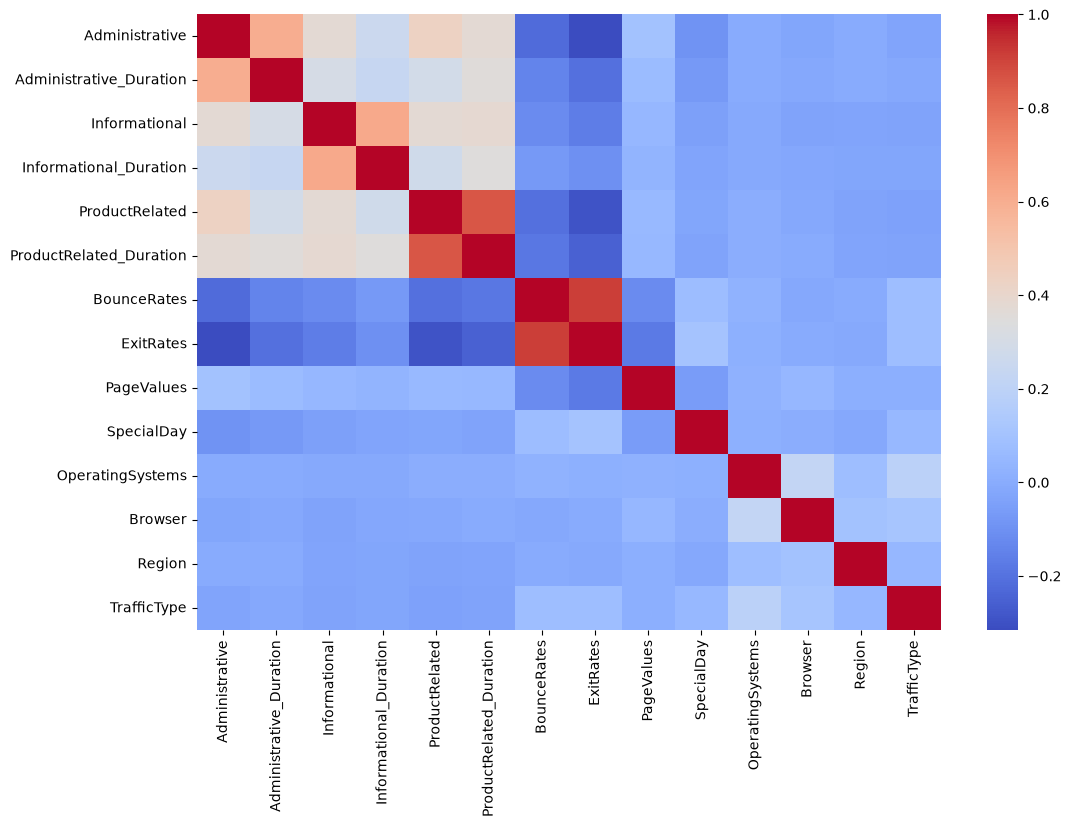

In [8]:
plt.figure(figsize=(12, 8))
sns.heatmap(data.select_dtypes("number").corr(), cmap="coolwarm")
plt.show()

## Encoding
Convert the text and True/False columns into numbers.

In [9]:
# Encoding the Data  
from sklearn.preprocessing import LabelEncoder
encod = LabelEncoder()
data["Month"] = encod.fit_transform(data["Month"])
data["VisitorType"] = encod.fit_transform(data["VisitorType"])
data["Weekend"] = encod.fit_transform(data["Weekend"])
data["Revenue"] = encod.fit_transform(data["Revenue"])

Check the data types again after encoding. All columns are numbers now.

In [10]:
data.info()

<class 'pandas.DataFrame'>
RangeIndex: 12330 entries, 0 to 12329
Data columns (total 18 columns):
 #   Column                   Non-Null Count  Dtype  
---  ------                   --------------  -----  
 0   Administrative           12330 non-null  int64  
 1   Administrative_Duration  12330 non-null  float64
 2   Informational            12330 non-null  int64  
 3   Informational_Duration   12330 non-null  float64
 4   ProductRelated           12330 non-null  int64  
 5   ProductRelated_Duration  12330 non-null  float64
 6   BounceRates              12330 non-null  float64
 7   ExitRates                12330 non-null  float64
 8   PageValues               12330 non-null  float64
 9   SpecialDay               12330 non-null  float64
 10  Month                    12330 non-null  int64  
 11  OperatingSystems         12330 non-null  int64  
 12  Browser                  12330 non-null  int64  
 13  Region                   12330 non-null  int64  
 14  TrafficType              12330 no

## Train Test split
Data is split into 80% training and 20% testing.

In [11]:
# Train Test split 

X = data.drop("Revenue",axis=1)
y = data["Revenue"]

from sklearn.model_selection import train_test_split

X_train,X_test,y_train,y_test = train_test_split(
    X,y ,test_size=0.2,random_state=42
)


## Scaling
StandardScaler is fitted on the train data only and then applied to the test data.

In [12]:
# Scaling the value 
from sklearn.preprocessing import StandardScaler
scalar = StandardScaler()
X_train_scal = scalar.fit_transform(X_train)
X_test_scal = scalar.transform(X_test)

## Decision Tree model
First model with `max_depth`, `min_samples_leaf` and `class_weight="balanced"` (because the data is imbalanced).

In [13]:
# model Selection 
from sklearn.tree import DecisionTreeClassifier
dt = DecisionTreeClassifier(max_depth=5,min_samples_leaf=20,class_weight="balanced")
dt.fit(X_train_scal,y_train)
y_pre = dt.predict(X_test_scal)

## Model evaluation

In [14]:
# metrices 
from sklearn.metrics import r2_score,mean_squared_error,confusion_matrix,classification_report
print("r2_score: ",r2_score(y_test,y_pre))
print("mean_squared_error : ",mean_squared_error(y_test,y_pre))
print("confusion_matrix : ",confusion_matrix(y_test,y_pre))
print("classification_report :",classification_report(y_test,y_pre))


r2_score:  -0.1620437956204379
mean_squared_error :  0.16139497161394972
confusion_matrix :  [[1717  338]
 [  60  351]]
classification_report :               precision    recall  f1-score   support

           0       0.97      0.84      0.90      2055
           1       0.51      0.85      0.64       411

    accuracy                           0.84      2466
   macro avg       0.74      0.84      0.77      2466
weighted avg       0.89      0.84      0.85      2466



## Post pruning
Find the possible `ccp_alpha` values for pruning the tree.

In [15]:
path = dt.cost_complexity_pruning_path(X_train_scal,y_train)
alphas = path.ccp_alphas
alphas

array([0.00000000e+00, 7.31606720e-15, 7.59912608e-05, 1.34137037e-04,
       2.17217839e-04, 2.99720486e-04, 3.14622516e-04, 4.59503780e-04,
       6.27561755e-04, 7.35571600e-04, 7.59327216e-04, 7.76561678e-04,
       9.39970644e-04, 9.51329390e-04, 1.01151814e-03, 1.01342725e-03,
       1.41737277e-03, 1.85862126e-03, 2.36857040e-03, 2.38098282e-03,
       2.72069865e-03, 3.96466755e-03, 4.32123382e-03, 5.31828624e-03,
       2.45750940e-02, 2.41143680e-01])

Search for the best settings using **cross-validation on the training data** with **F1 score** (not accuracy, and not the test data).
We try different values of `ccp_alpha` (pruning), `max_depth` and `min_samples_leaf`, and keep `class_weight="balanced"`.

In [16]:
from sklearn.model_selection import GridSearchCV

params = {
    "ccp_alpha": [0, 0.0001, 0.0003, 0.0005, 0.001, 0.002],
    "max_depth": [4, 5, 6, 8, 10],
    "min_samples_leaf": [10, 20, 40]
}

grid = GridSearchCV(
    DecisionTreeClassifier(class_weight="balanced", random_state=42),
    param_grid=params,
    scoring="f1",
    cv=5,
    n_jobs=-1
)
grid.fit(X_train_scal, y_train)

print("Best parameters : ", grid.best_params_)
print("Best CV F1 score : ", grid.best_score_)

Best parameters :  {'ccp_alpha': 0, 'max_depth': 5, 'min_samples_leaf': 40}
Best CV F1 score :  0.6338602485004007


## Final model after pruning and hyperparameter tuning
Use the best settings found above. The test data is used only now.

In [18]:
modelnew = grid.best_estimator_
y_pre = modelnew.predict(X_test_scal)

# metrices
from sklearn.metrics import accuracy_score,precision_score,recall_score,f1_score,confusion_matrix,classification_report
print("accuracy_score : ",accuracy_score(y_test,y_pre))
print("precision Score : ",precision_score(y_test,y_pre))
print("recall Score : ",recall_score(y_test,y_pre))
print("f1_score : ",f1_score(y_test,y_pre))
print("confusion_matrix : \n",confusion_matrix(y_test,y_pre))
print("classification_report : \n",classification_report(y_test,y_pre))

accuracy_score :  0.8381995133819952
precision Score :  0.508695652173913
recall Score :  0.8540145985401459
f1_score :  0.6376021798365122
confusion_matrix : 
 [[1716  339]
 [  60  351]]
classification_report : 
               precision    recall  f1-score   support

           0       0.97      0.84      0.90      2055
           1       0.51      0.85      0.64       411

    accuracy                           0.84      2466
   macro avg       0.74      0.84      0.77      2466
weighted avg       0.89      0.84      0.85      2466



## Conclusion
- The data is imbalanced, so F1 score is used.
- In the old version the F1 score dropped to 0.579 because `class_weight` was removed and alpha was chosen by accuracy on the test data.
- Now `class_weight="balanced"` is kept and the pruning settings are chosen by cross-validated F1, so the model finds more real buyers (higher recall) and the F1 score improves.
- Compare the final F1 score with 0.55 (benchmark) and with Model 1 (0.64) after running.

In [19]:
import joblib
joblib.dump(modelnew, "model.pkl")
joblib.dump(scalar, "scaler.pkl")
joblib.dump(list(X.columns), "columns.pkl")

['columns.pkl']